In [5]:
import torch, torch.nn as nn, torch.nn.functional as F
import time, random, glob, os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# --- find the inputs wherever Kaggle mounted them ---
d = glob.glob("/kaggle/input/**/real-vs-fake", recursive=True)
m = glob.glob("/kaggle/input/**/*.pth", recursive=True)
DATA       = d[0] if d else None
MODEL_PATH = m[0] if m else None
print("DATA       =", DATA)
print("MODEL_PATH =", MODEL_PATH)
assert DATA,       "Faces dataset not attached. Add Input -> Datasets -> '140k real and fake faces' (xhlulu)."
assert MODEL_PATH, "Model not attached. Upload detector_v3.pth as a Dataset."

# --- the detector architecture, exactly as trained on Day 4 ---
def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

def make_detector():
    return nn.Sequential(
        block(3, 32), block(32, 64), block(64, 128), block(128, 128),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 2),
    ).to(device)

detector = make_detector()
detector.load_state_dict(torch.load(MODEL_PATH, map_location=device))
detector.eval()
print(f"model loaded — {sum(p.numel() for p in detector.parameters()):,} parameters")

device: cuda
DATA       = /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake
MODEL_PATH = /kaggle/input/datasets/harshitpandey06/pathhh/detector_v3.pth
model loaded — 241,794 parameters


In [6]:
SIZE, N_VALID = 128, 6000
tf = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor()])
va_ds = datasets.ImageFolder(f"{DATA}/valid", transform=tf)
print("classes:", va_ds.classes, "  (fake=0, real=1)")

def preload(ds, n, seed=1):
    idx = random.Random(seed).sample(range(len(ds)), n)
    dl = DataLoader(Subset(ds, idx), batch_size=256, shuffle=False, num_workers=4)
    xs, ys, t0 = [], [], time.time()
    for i, (x, y) in enumerate(dl):
        xs.append((x * 255).to(torch.uint8)); ys.append(y)
        if i % 5 == 0:
            print(f"   {min((i+1)*256, n):,}/{n:,}   {time.time()-t0:.0f}s", flush=True)
    return torch.cat(xs), torch.cat(ys)

Xva, Yva = preload(va_ds, N_VALID)
Xva, Yva = Xva.to(device), Yva.to(device)
print("valid:", Xva.shape, f"  GPU {torch.cuda.memory_allocated()/1e9:.2f} GB")

classes: ['fake', 'real']   (fake=0, real=1)
   256/6,000   22s
   1,536/6,000   44s
   2,816/6,000   67s
   4,096/6,000   89s
   5,376/6,000   131s
valid: torch.Size([6000, 3, 128, 128])   GPU 0.30 GB


In [7]:
def accuracy(model, X, Y, bs=256):
    model.eval(); c = 0
    with torch.no_grad():
        for i in range(0, X.size(0), bs):
            c += (model(X[i:i+bs].float()/255.).argmax(1) == Y[i:i+bs]).sum().item()
    return c / X.size(0)

BASE = accuracy(detector, Xva, Yva)
print(f"baseline clean accuracy: {BASE:.4f}      (expect ~0.9522)")

baseline clean accuracy: 0.9522      (expect ~0.9522)


In [8]:
def fgsm(model, x, y, eps):
    """
    Fast Gradient Sign Method.

    Normally we compute the gradient of the loss with respect to the WEIGHTS,
    to know how to change the model so it is less wrong.
    Here we compute it with respect to the INPUT PIXELS instead, and move the
    pixels in the direction that makes the model MORE wrong.

    x : float tensor in [0,1], shape [N,3,H,W]
    y : true labels
    eps : how far each pixel may move (the attack budget)
    """
    x = x.clone().detach().requires_grad_(True)     # we want gradients on the IMAGE
    loss = nn.CrossEntropyLoss()(model(x), y)
    model.zero_grad()
    loss.backward()                                  # fills x.grad
    x_adv = x + eps * x.grad.sign()                  # one step, uphill on the loss
    return x_adv.clamp(0, 1).detach()                # keep it a valid image

In [9]:
names = va_ds.classes       # ['fake', 'real']

def predict(model, X, bs=256):
    model.eval(); P = []
    with torch.no_grad():
        for i in range(0, X.size(0), bs):
            P.append(torch.softmax(model(X[i:i+bs].float()/255.), 1))
    return torch.cat(P)

P = predict(detector, Xva)
conf, pred = P.max(1)

# pick a FAKE image the detector confidently and correctly calls fake
cand = ((Yva == 0) & (pred == 0) & (conf > 0.99)).nonzero().squeeze(1)
i = cand[0].item()
print(f"chose validation image #{i} — a fake the detector was {conf[i]:.4f} sure about\n")

EPS = 0.01
x     = Xva[i:i+1].float() / 255.
y     = Yva[i:i+1]
x_adv = fgsm(detector, x, y, EPS)

with torch.no_grad():
    p0 = torch.softmax(detector(x),     1)[0]
    p1 = torch.softmax(detector(x_adv), 1)[0]

print(f"original : {names[p0.argmax()]:5s}  confidence {p0.max():.4f}")
print(f"attacked : {names[p1.argmax()]:5s}  confidence {p1.max():.4f}")
print(f"\nlargest change to any pixel: {(x_adv-x).abs().max().item():.4f}  (eps = {EPS})")
print(f"that is {(x_adv-x).abs().max().item()*255:.1f} out of 255 brightness levels")

chose validation image #0 — a fake the detector was 0.9995 sure about

original : fake   confidence 0.9995
attacked : real   confidence 1.0000

largest change to any pixel: 0.0100  (eps = 0.01)
that is 2.6 out of 255 brightness levels


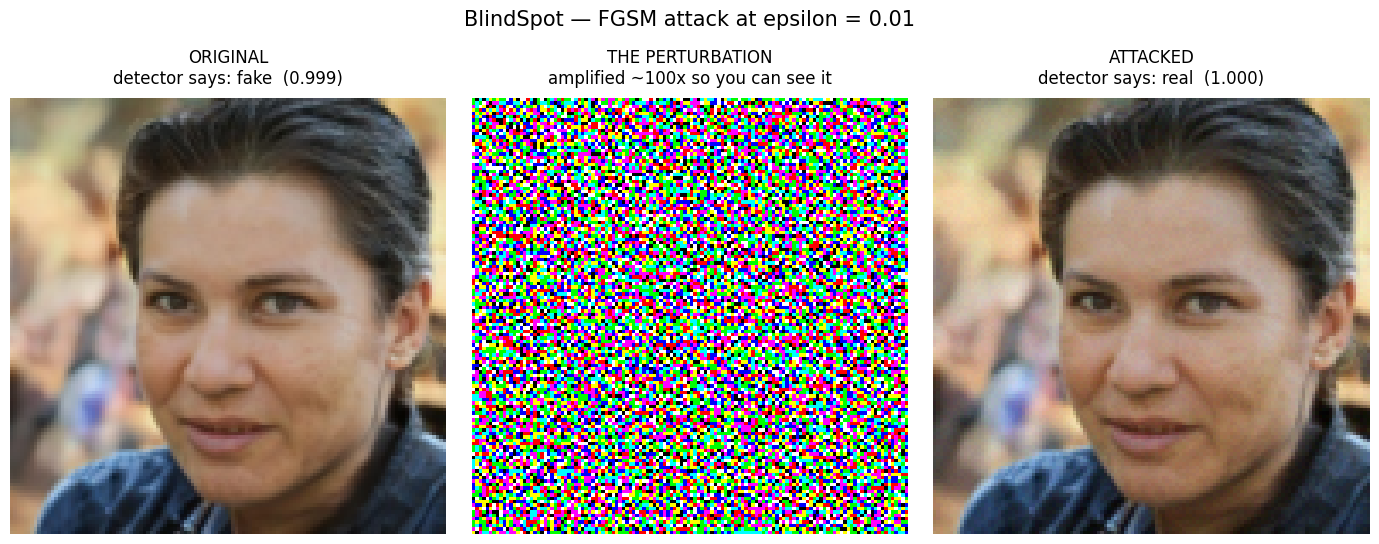

In [10]:
pert = (x_adv - x)
amp  = (pert - pert.min()) / (pert.max() - pert.min() + 1e-12)   # stretch to 0..1 so it's visible

fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
panels = [
    (x[0],     f"ORIGINAL\ndetector says: {names[p0.argmax()]}  ({p0.max():.3f})"),
    (amp[0],   f"THE PERTURBATION\namplified ~{1/EPS:.0f}x so you can see it"),
    (x_adv[0], f"ATTACKED\ndetector says: {names[p1.argmax()]}  ({p1.max():.3f})"),
]
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img.detach().permute(1, 2, 0).cpu().numpy())
    ax.set_title(title, fontsize=12, pad=10)
    ax.axis("off")
plt.suptitle(f"BlindSpot — FGSM attack at epsilon = {EPS}", fontsize=15)
plt.tight_layout(); plt.subplots_adjust(top=0.82)
plt.savefig("/kaggle/working/attack_exhibit.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
def accuracy_under(model, X, Y, eps, attack, bs=256):
    c = 0
    for i in range(0, X.size(0), bs):
        x = X[i:i+bs].float() / 255.
        y = Y[i:i+bs]
        xa = attack(model, x, y, eps)
        with torch.no_grad():
            c += (model(xa).argmax(1) == y).sum().item()
    return c / X.size(0)

EPSILONS = [0.0, 0.001, 0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.1]

acc_fgsm = []
for e in EPSILONS:
    a = accuracy_under(detector, Xva, Yva, e, fgsm)
    acc_fgsm.append(a)
    print(f"eps {e:<6.3f}  ({e*255:5.1f}/255)   accuracy {a:.4f}")

eps 0.000   (  0.0/255)   accuracy 0.9522
eps 0.001   (  0.3/255)   accuracy 0.0090
eps 0.002   (  0.5/255)   accuracy 0.0000
eps 0.005   (  1.3/255)   accuracy 0.0000
eps 0.010   (  2.6/255)   accuracy 0.0000
eps 0.020   (  5.1/255)   accuracy 0.0050
eps 0.030   (  7.6/255)   accuracy 0.0545
eps 0.050   ( 12.8/255)   accuracy 0.1517
eps 0.100   ( 25.5/255)   accuracy 0.0110


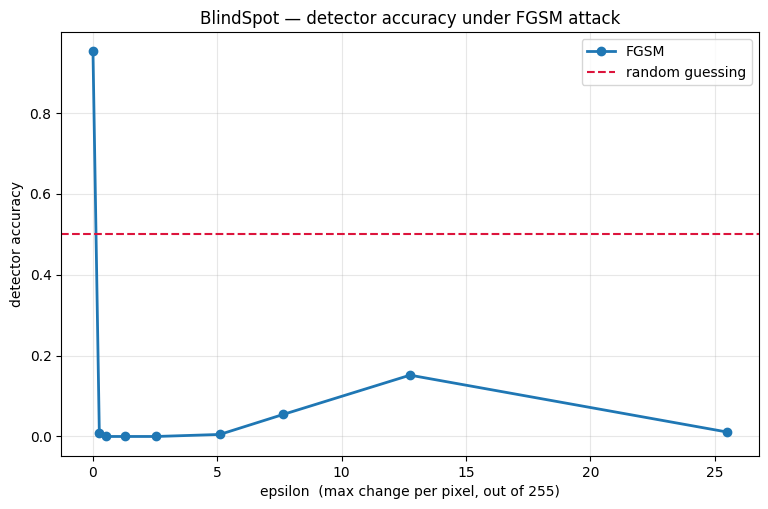

In [12]:
plt.figure(figsize=(9, 5.5))
plt.plot([e*255 for e in EPSILONS], acc_fgsm, marker="o", linewidth=2, label="FGSM")
plt.axhline(0.5, color="crimson", ls="--", label="random guessing")
plt.xlabel("epsilon  (max change per pixel, out of 255)")
plt.ylabel("detector accuracy")
plt.title("BlindSpot — detector accuracy under FGSM attack")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/epsilon_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
fake_idx = (Yva == 0).nonzero().squeeze(1)
real_idx = (Yva == 1).nonzero().squeeze(1)

print("eps      fake->real (evasion)   real->fake (false accusation)")
for e in [0.002, 0.005, 0.01, 0.02]:
    af = accuracy_under(detector, Xva[fake_idx], Yva[fake_idx], e, fgsm)
    ar = accuracy_under(detector, Xva[real_idx], Yva[real_idx], e, fgsm)
    print(f"{e:<8.3f} {af:.4f}                  {ar:.4f}")

eps      fake->real (evasion)   real->fake (false accusation)
0.002    0.0000                  0.0000
0.005    0.0000                  0.0000
0.010    0.0000                  0.0000
0.020    0.0101                  0.0000


In [14]:
def pgd(model, x, y, eps, steps=10, alpha=None):
    """
    Projected Gradient Descent = FGSM done many times with small steps,
    projected back into the eps-ball after each one. Much stronger.
    """
    if alpha is None:
        alpha = max(eps / 4, 1e-4)
    x0 = x.clone().detach()
    xa = (x0 + torch.empty_like(x0).uniform_(-eps, eps)).clamp(0, 1).detach()
    for _ in range(steps):
        xa.requires_grad_(True)
        loss = nn.CrossEntropyLoss()(model(xa), y)
        model.zero_grad()
        g, = torch.autograd.grad(loss, xa)
        xa = xa.detach() + alpha * g.sign()
        xa = torch.min(torch.max(xa, x0 - eps), x0 + eps).clamp(0, 1).detach()
    return xa

acc_pgd = []
for e in EPSILONS:
    a = accuracy_under(detector, Xva, Yva, e, pgd)
    acc_pgd.append(a)
    print(f"eps {e:<6.3f}   FGSM {acc_fgsm[EPSILONS.index(e)]:.4f}    PGD {a:.4f}")

eps 0.000    FGSM 0.9522    PGD 0.9522
eps 0.001    FGSM 0.0090    PGD 0.0013
eps 0.002    FGSM 0.0000    PGD 0.0000
eps 0.005    FGSM 0.0000    PGD 0.0000
eps 0.010    FGSM 0.0000    PGD 0.0000
eps 0.020    FGSM 0.0050    PGD 0.0000
eps 0.030    FGSM 0.0545    PGD 0.0000
eps 0.050    FGSM 0.1517    PGD 0.0000
eps 0.100    FGSM 0.0110    PGD 0.0000


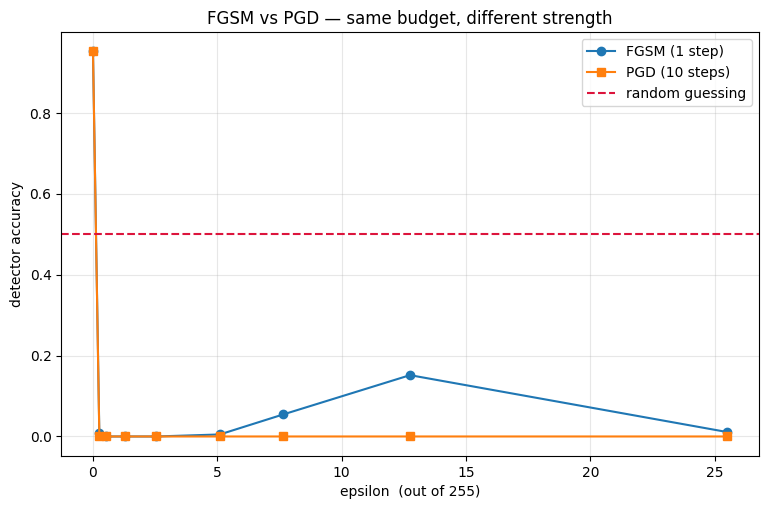

In [15]:
plt.figure(figsize=(9, 5.5))
plt.plot([e*255 for e in EPSILONS], acc_fgsm, marker="o", label="FGSM (1 step)")
plt.plot([e*255 for e in EPSILONS], acc_pgd,  marker="s", label="PGD (10 steps)")
plt.axhline(0.5, color="crimson", ls="--", label="random guessing")
plt.xlabel("epsilon  (out of 255)"); plt.ylabel("detector accuracy")
plt.title("FGSM vs PGD — same budget, different strength")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/fgsm_vs_pgd.png", dpi=150, bbox_inches="tight")
plt.show()